<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 8: Bayes' Theorem and a Bayesian Network for Diagnosis</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.4 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Apply Bayes' theorem to a medical-test diagnosis problem and implement the Burglary–Alarm Bayesian network with exact inference by enumeration and approximate inference by sampling.</div>

## 📘 Theory

**Bayes' theorem:** $P(H\mid E)=\dfrac{P(E\mid H)P(H)}{P(E)}$.
A **Bayesian network** is a DAG with a CPT per node; the joint is $\prod_i P(x_i\mid parents(X_i))$.
**Enumeration:** $P(X\mid e)=\alpha\sum_y P(X,e,y)$. **Rejection sampling** estimates the same posterior from random samples.

## 🧭 Algorithm

1. Encode priors and conditional probabilities.
2. Compute the posterior with Bayes' rule and study how it varies with the prior.
3. Encode the Burglary network CPTs; compute the joint probability of a full assignment.
4. Compute P(Burglary | JohnCalls, MaryCalls) by enumeration and compare with rejection sampling.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

In [2]:
def bayes(prior, sens, fpr):
    evidence = sens * prior + fpr * (1 - prior)
    return sens * prior / evidence, evidence
post, ev = bayes(prior=0.01, sens=0.90, fpr=0.05)
print(f"P(+) = {ev:.4f}")
print(f"P(Disease | +) = {post:.4f}  →  only {post:.1%} despite a 90%-sensitive test (base-rate effect)")
post2, _ = bayes(prior=post, sens=0.90, fpr=0.05)
print(f"After a second independent positive test: {post2:.1%}")

P(+) = 0.0585
P(Disease | +) = 0.1538  →  only 15.4% despite a 90%-sensitive test (base-rate effect)
After a second independent positive test: 76.6%


In [3]:
priors = np.linspace(0.001, 0.5, 300)
plt.figure(figsize=(6.8, 3.8))
for sens, fpr, c in ((0.90, 0.05, NAVY), (0.99, 0.01, TEAL), (0.80, 0.10, CRIMSON)):
    plt.plot(priors, [bayes(p, sens, fpr)[0] for p in priors], color=c, lw=2.5, label=f"sens={sens}, FPR={fpr}")
plt.axvline(0.01, color=GOLD, ls="--"); plt.text(0.015, 0.05, "prevalence 1%", color=GOLD)
plt.xlabel("prior P(Disease)"); plt.ylabel("posterior P(Disease | +)"); plt.legend(frameon=False); plt.title("Posterior depends strongly on the prior")
plt.tight_layout(); plt.savefig(f"{FIG}/exp08_posterior_vs_prior.png", dpi=130); plt.show()

### Burglary–Alarm Bayesian network

In [4]:
import itertools
P_B, P_E = 0.001, 0.002
P_A = {(True, True): 0.95, (True, False): 0.94, (False, True): 0.29, (False, False): 0.001}
P_J = {True: 0.90, False: 0.05}; P_M = {True: 0.70, False: 0.01}
def p(v, prob): return prob if v else 1 - prob
def joint(b, e, a, j, m):
    return p(b, P_B) * p(e, P_E) * p(a, P_A[(b, e)]) * p(j, P_J[a]) * p(m, P_M[a])
print(f"P(j, m, a, ¬b, ¬e) = {joint(False, False, True, True, True):.6f}")

def enumerate_query(var, evidence):
    names = ["B", "E", "A", "J", "M"]; dist = {}
    for val in (True, False):
        tot = 0.0
        for vals in itertools.product((True, False), repeat=5):
            asg = dict(zip(names, vals))
            if asg[var] != val or any(asg[k] != v for k, v in evidence.items()): continue
            tot += joint(*vals)
        dist[val] = tot
    z = sum(dist.values()); return {k: v / z for k, v in dist.items()}
for q, ev in (("B", {"J": True, "M": True}), ("E", {"J": True, "M": True}), ("A", {"J": True, "M": True}), ("B", {"J": True, "M": False})):
    r = enumerate_query(q, ev); print(f"P({q}=T | {', '.join(f'{k}={v}' for k, v in ev.items())}) = {r[True]:.4f}")

P(j, m, a, ¬b, ¬e) = 0.000628
P(B=T | J=True, M=True) = 0.2842
P(E=T | J=True, M=True) = 0.1761
P(A=T | J=True, M=True) = 0.7607
P(B=T | J=True, M=False) = 0.0051


Exact P(B | j, m) = 0.2842;  likelihood weighting (100k samples) ≈ 0.2975


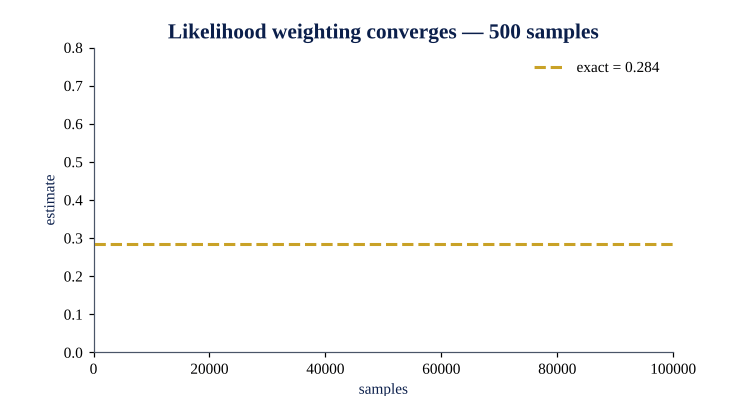

In [5]:
rng = np.random.default_rng(0)
def prior_sample():
    b = rng.random() < P_B; e = rng.random() < P_E; a = rng.random() < P_A[(b, e)]
    return b, e, a, rng.random() < P_J[a], rng.random() < P_M[a]
def likelihood_weighting(n):
    wsum = {True: 0.0, False: 0.0}; est = []
    for i in range(1, n + 1):
        b = rng.random() < P_B; e = rng.random() < P_E; a = rng.random() < P_A[(b, e)]
        w = P_J[a] * P_M[a]; wsum[b] += w
        if i % 500 == 0: est.append(wsum[True] / (wsum[True] + wsum[False]))
    return est
exact = enumerate_query("B", {"J": True, "M": True})[True]
est = likelihood_weighting(100_000)
print(f"Exact P(B | j, m) = {exact:.4f};  likelihood weighting (100k samples) ≈ {est[-1]:.4f}")
fig, ax = plt.subplots(figsize=(6.8, 3.6)); xs = np.arange(1, len(est) + 1) * 500
line, = ax.plot([], [], color=NAVY, lw=2); ax.axhline(exact, color=GOLD, ls="--", lw=2, label=f"exact = {exact:.3f}")
ax.set_xlim(0, xs[-1]); ax.set_ylim(0, 0.8); ax.set_xlabel("samples"); ax.set_ylabel("estimate"); ax.legend(frameon=False)
def upd(k):
    line.set_data(xs[:k + 1], est[:k + 1]); ax.set_title(f"Likelihood weighting converges — {xs[k]:,} samples"); return line,
gif = save_gif(animation.FuncAnimation(fig, upd, frames=range(0, len(est), 5)), "exp08_sampling_convergence.gif", fps=6)
display(Image(filename=gif))

In [6]:
import networkx as nx
G = nx.DiGraph([("Burglary","Alarm"),("Earthquake","Alarm"),("Alarm","JohnCalls"),("Alarm","MaryCalls")])
pos = {"Burglary":(0,1),"Earthquake":(2,1),"Alarm":(1,0.5),"JohnCalls":(0,0),"MaryCalls":(2,0)}
plt.figure(figsize=(6, 3.6))
nx.draw(G, pos, with_labels=True, node_color=[GOLDL, GOLDL, NAVY, MIST, MIST], node_size=3800, edgecolors=NAVY,
        font_color="black", font_family="serif", font_size=10, arrowsize=18, edge_color=TEAL, width=2)
plt.title("Bayesian network structure"); plt.savefig(f"{FIG}/exp08_bayesnet.png", dpi=130, bbox_inches="tight"); plt.show()

## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>A positive result from a 90%-sensitive test with 1% prevalence gives only a 15.4% chance of disease. In the alarm network, P(Burglary | JohnCalls, MaryCalls) = 0.284 by exact enumeration, and likelihood weighting converges to the same value.</div>

## 🎤 Viva Questions

1. State Bayes' theorem and name each term.
2. Explain the base-rate fallacy with the medical test example.
3. Why is a Bayesian network more compact than the full joint distribution?
4. What is the complexity of inference by enumeration?
5. How does likelihood weighting differ from rejection sampling?